# 01 · Inspección del límite provincial de Cusco

**Objetivo:** abrir `data/raw/Provincia/PROVINCIA.gpkg`, revisar su contenido y aislar la **provincia de Cusco** (no el departamento ni otras provincias).

Este notebook **solo lee** los datos; no modifica `data/raw/`.

**Clave del filtro:** el nombre `CUSCO` aparece dos veces: como departamento y como provincia. Por eso filtro por **códigos**:
- `ccdd = "08"` → departamento de Cusco
- `ccpp = "01"` → provincia de Cusco dentro de ese departamento

**Fuente del límite:** INEI, límites provinciales. La columna `fuente` del GeoPackage dice "V Censo Nacional Económico"; hay que confirmar que es el mismo producto del INEI.


In [14]:
# creamos una carpeta para guardar los datos de salida
import ee
ee.Initialize(project="viirs-peru")

ee.data.listAssets({"parent": "projects/viirs-peru/assets"})

{'assets': [{'type': 'FOLDER',
   'name': 'projects/viirs-peru/assets/tmp',
   'id': 'projects/viirs-peru/assets/tmp',
   'updateTime': '2026-10-23T18:05:44.886107Z'}]}

## 1. Localizar el archivo

In [15]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pyogrio


def buscar_raiz(inicio=None):
    """Sube por las carpetas hasta encontrar la que contiene data/raw."""
    inicio = Path(inicio or Path.cwd()).resolve()
    for carpeta in [inicio, *inicio.parents]:
        if (carpeta / "data" / "raw" / "Provincia" / "PROVINCIA.gpkg").is_file():
            return carpeta
    raise FileNotFoundError("No encuentro data/raw/Provincia/PROVINCIA.gpkg desde esta ubicación.")


RAIZ = buscar_raiz()
GPKG = RAIZ / "data" / "raw" / "Provincia" / "PROVINCIA.gpkg"

print("Raíz del proyecto:", RAIZ)
print("Archivo existe:", GPKG.exists())


Raíz del proyecto: F:\Cobertura de suelo
Archivo existe: True


## 2. Capas del GeoPackage

In [16]:
# Cada fila: [nombre de la capa, tipo de geometría]
capas = pyogrio.list_layers(GPKG)
print("Capas encontradas:", len(capas))
for nombre, tipo in capas:
    print(f"  - {nombre}  ({tipo})")

Capas encontradas: 1
  - PROVINCIA  (MultiPolygon)


## 3. Lectura, CRS, columnas y número de polígonos

In [17]:
capa = capas[0][0]
gdf = gpd.read_file(GPKG, layer=capa)

print("Capa leída:", capa)
print("CRS:", gdf.crs)
print("Registros:", len(gdf))
print("Tipos de geometría:", gdf.geom_type.value_counts().to_dict())
print("Columnas:", list(gdf.columns))

gdf.drop(columns=gdf.geometry.name).head()

Capa leída: PROVINCIA
CRS: EPSG:4326
Registros: 196
Tipos de geometría: {'MultiPolygon': 196}
Columnas: ['ccdd', 'ccpp', 'nombprov', 'fuente', 'nombdep', 'geometry']


,ccdd,ccpp,nombprov,fuente,nombdep
0,01,01,CHACHAPOYAS,V Censo Nacional Economico,AMAZONAS
1,01,02,BAGUA,V Censo Nacional Economico,AMAZONAS
2,01,03,BONGARA,V Censo Nacional Economico,AMAZONAS
3,01,04,CONDORCANQUI,V Censo Nacional Economico,AMAZONAS
4,01,05,LUYA,V Censo Nacional Economico,AMAZONAS


## 4. Revisar los códigos del departamento de Cusco

Así se ve qué provincias pertenecen al departamento (`ccdd = 08`) y cómo se llama cada una.

In [18]:
print("Departamentos distintos:", gdf["ccdd"].nunique())
print("Provincias totales (Perú):", len(gdf))

gdf.loc[gdf["ccdd"] == "08", ["ccdd", "ccpp", "nombdep", "nombprov"]] \
    .sort_values("ccpp") \
    .reset_index(drop=True)

Departamentos distintos: 25
Provincias totales (Perú): 196


,ccdd,ccpp,nombdep,nombprov
0,08,01,CUSCO,CUSCO
1,08,02,CUSCO,ACOMAYO
2,08,03,CUSCO,ANTA
3,08,04,CUSCO,CALCA
4,08,05,CUSCO,CANAS
5,08,06,CUSCO,CANCHIS
6,08,07,CUSCO,CHUMBIVILCAS
7,08,08,CUSCO,ESPINAR
8,08,09,CUSCO,LA CONVENCION
9,08,10,CUSCO,PARURO


## 5. Filtrar la provincia de Cusco

Se espera **exactamente 1 registro**. Si no, el notebook se detiene.

In [19]:
CCDD_CUSCO = "08"  # departamento de Cusco
CCPP_CUSCO = "01"  # provincia de Cusco dentro del departamento

prov = gdf[(gdf["ccdd"] == CCDD_CUSCO) & (gdf["ccpp"] == CCPP_CUSCO)].copy()
assert len(prov) == 1, f"Esperaba 1 provincia y encontré {len(prov)}"

prov[["ccdd", "ccpp", "nombdep", "nombprov", "fuente"]]

,ccdd,ccpp,nombdep,nombprov,fuente
67,08,01,CUSCO,CUSCO,V Censo Nacional Economico


## 6. Validez de la geometría, partes y área

El área se calcula en **UTM zona 19S (EPSG:32719)**, la zona que corresponde a Cusco, porque el CRS del archivo es geográfico (grados).

In [20]:
geom = prov.geometry.iloc[0]
partes = len(geom.geoms) if geom.geom_type == "MultiPolygon" else 1
area_km2 = prov.to_crs(epsg=32719).area.iloc[0] / 1e6

print("Tipo de geometría:", geom.geom_type)
print("Válida:", geom.is_valid, "| Vacía:", geom.is_empty)
print("Número de polígonos (partes):", partes)
print(f"Área aproximada: {area_km2:,.1f} km²  (EPSG:32719)")
print("Límites (lon/lat):", [round(v, 4) for v in prov.total_bounds])

Tipo de geometría: MultiPolygon
Válida: True | Vacía: False
Número de polígonos (partes): 1
Área aproximada: 530.1 km²  (EPSG:32719)
Límites (lon/lat): [np.float64(-72.168), np.float64(-13.6492), np.float64(-71.8046), np.float64(-13.4295)]


## 7. Mapa de verificación

Izquierda: el departamento como contexto, con la provincia de Cusco resaltada.
Derecha: solo la provincia de Cusco.

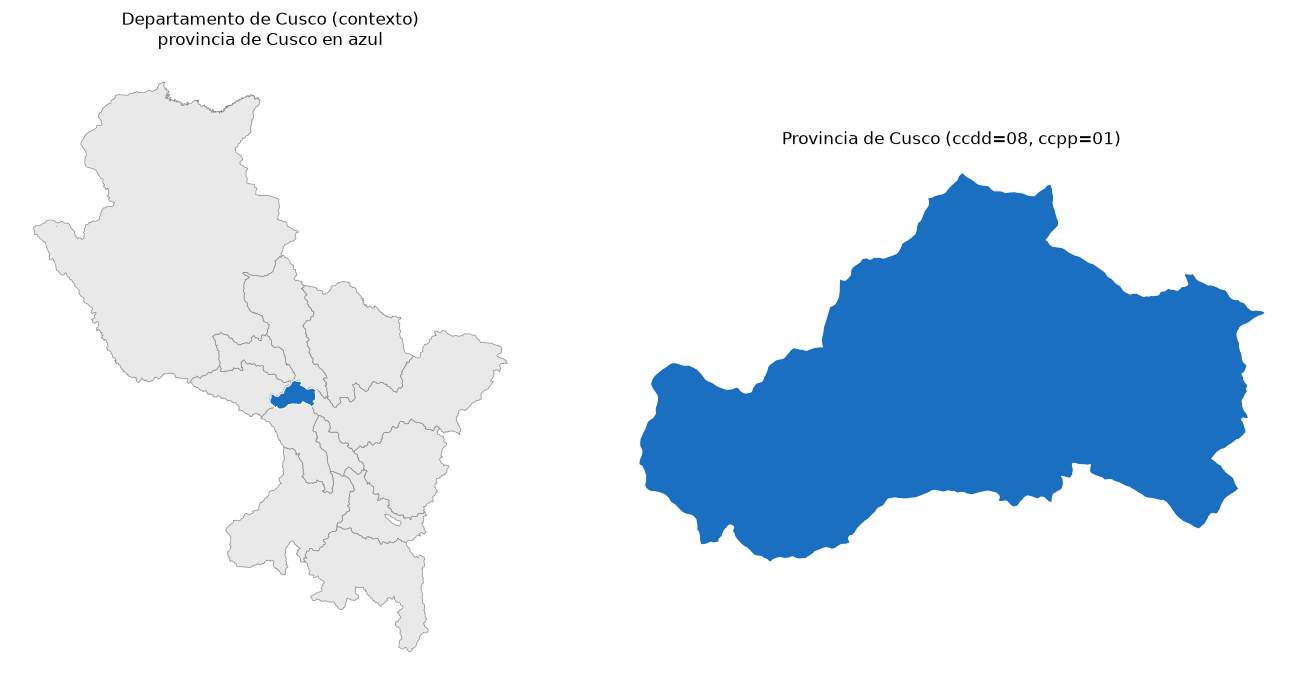

In [21]:
dpto = gdf[gdf["ccdd"] == CCDD_CUSCO]

fig, ejes = plt.subplots(1, 2, figsize=(14, 7))

dpto.plot(ax=ejes[0], color="#e9e9e9", edgecolor="#8a8a8a", linewidth=0.5)
prov.plot(ax=ejes[0], color="#1a6fc0", edgecolor="white", linewidth=0.8)
ejes[0].set_title("Departamento de Cusco (contexto)\nprovincia de Cusco en azul")

prov.plot(ax=ejes[1], color="#1a6fc0", edgecolor="white", linewidth=0.8)
ejes[1].set_title("Provincia de Cusco (ccdd=08, ccpp=01)")

for ax in ejes:
    ax.set_axis_off()

plt.tight_layout()
plt.show()

## 8 · Exportar el área de estudio

Hasta esta versión el notebook solo verificaba el límite y no dejaba ningún archivo. Eso obligaba a
que los notebooks 02 a 06 volvieran a abrir `PROVINCIA.gpkg` y a repetir el filtro
`ccdd = 08` / `ccpp = 01` cada uno por su cuenta. Cinco definiciones del mismo polígono: si alguien
cambia el criterio en una, las demás no se enteran.

A partir de aquí el área de estudio **se produce una vez y se consume en todos lados**.

### Qué se exporta y por qué simplificada

La geometría se simplifica con tolerancia de 0.0001° (unos 11 m, menos de medio píxel de Landsat)
antes de exportar. No es por precisión sino por costo: cada consulta a Earth Engine lleva la
geometría consigo, y un polígono con miles de vértices encarece todas las operaciones sin aportar
nada a 30 m de resolución.

Se exporta **la versión simplificada en los dos formatos**, a propósito: así el GeoJSON y el asset
describen exactamente el mismo polígono y no hay dos áreas de estudio ligeramente distintas
circulando por el proyecto. La geometría original siempre queda disponible en `PROVINCIA.gpkg`.

| Salida | Para qué |
|---|---|
| `outputs/01_area_de_estudio/area_estudio.geojson` | Registro del área y uso en herramientas de escritorio (QGIS) |
| Asset `cusco_01_aoi` | Lo que leen los notebooks 02 a 06 |

In [ ]:
import json as _json

import ee

GEE_PROJECT = "viirs-peru"
ASSET_AOI = f"projects/{GEE_PROJECT}/assets/cusco_01_aoi"
TOL_SIMPLIFICAR = 0.0001        # grados (~11 m). Menos de medio píxel de Landsat.
EXPORTAR_ASSET = False          # ponlo en True una sola vez

SALIDA = RAIZ / "outputs" / "01_area_de_estudio"
SALIDA.mkdir(parents=True, exist_ok=True)

# --- GeoJSON (siempre) -----------------------------------------------------
geom_simple = prov.geometry.iloc[0].simplify(TOL_SIMPLIFICAR, preserve_topology=True)
aoi_gdf = prov.copy()
aoi_gdf["geometry"] = [geom_simple]

ruta_geojson = SALIDA / "area_estudio.geojson"
aoi_gdf.to_file(ruta_geojson, driver="GeoJSON")

vertices_antes = len(prov.geometry.iloc[0].exterior.coords) if prov.geometry.iloc[0].geom_type == "Polygon" else sum(
    len(g.exterior.coords) for g in prov.geometry.iloc[0].geoms)
vertices_despues = len(geom_simple.exterior.coords) if geom_simple.geom_type == "Polygon" else sum(
    len(g.exterior.coords) for g in geom_simple.geoms)

print("GeoJSON guardado en:", ruta_geojson)
print(f"Vértices: {vertices_antes:,} → {vertices_despues:,} tras simplificar")
print(f"Área original   : {area_km2:,.2f} km²")
print(f"Área simplificada: {aoi_gdf.to_crs(epsg=32719).area.iloc[0] / 1e6:,.2f} km²")

# --- Asset de Earth Engine (una sola vez) ----------------------------------
if EXPORTAR_ASSET:
    try:
        ee.Initialize(project=GEE_PROJECT)
    except Exception:
        ee.Authenticate()
        ee.Initialize(project=GEE_PROJECT)

    aoi_ee = ee.Geometry(geom_simple.__geo_interface__)
    fc = ee.FeatureCollection([ee.Feature(aoi_ee, {
        "nombre": str(prov["nombprov"].iloc[0]),
        "departamento": str(prov["nombdep"].iloc[0]),
        "ccdd": CCDD_CUSCO,
        "ccpp": CCPP_CUSCO,
        "fuente": str(prov["fuente"].iloc[0]),
        "area_km2": round(float(area_km2), 2),
        "simplificado_grados": TOL_SIMPLIFICAR,
    })])

    tarea = ee.batch.Export.table.toAsset(
        collection=fc, description="cusco_01_aoi", assetId=ASSET_AOI)
    tarea.start()
    print("\nTarea de exportación lanzada:", tarea.id)
    print("Destino:", ASSET_AOI)
    print("Seguimiento: pestaña Tasks del Code Editor, o ee.batch.Task.list()")
else:
    print("\nEXPORTAR_ASSET = False.")
    print("Ponlo en True y ejecuta esta celda UNA VEZ para crear", ASSET_AOI)
    print("Los notebooks 02 a 06 leen el área de estudio de ese asset.")

GeoJSON guardado en: F:\Cobertura de suelo\outputs\01_area_de_estudio\area_estudio.geojson
Vértices: 1,148 → 586 tras simplificar
Área original   : 530.15 km²
Área simplificada: 530.13 km²

Tarea de exportación lanzada: VUPS3CQZMEZ6MXFU7BPAYTJP
Destino: projects/viirs-peru/assets/cusco_01_aoi
Seguimiento: pestaña Tasks del Code Editor, o ee.batch.Task.list()


## Siguiente paso

Con el límite provincial ya verificado, el notebook `02_revision_fuentes.ipynb` usa la misma geometría para conectarse a Google Earth Engine.